# S-PLUS × eROSITA × DES: catalog exploration

Goal (later): the $L_X$–$M$ scaling relation, with eROSITA X-ray luminosities, S-PLUS clusters, and weak-lensing masses from the DES Y3 metacal shape catalog. This notebook only looks at the data.

- Cluster catalog: `~/destacking_data/lx_splus_erosita_des/gas_mass_uniqueIDs_AME_r200.fits` (one FITS table, `Joined`, 3813 rows × 92 columns, made with STILTS/TOPCAT on 2026-08-17).
- Sources: `~/destacking_data/real_data/metacal_filtered.npz` (DES Y3 metacal, the same file the WaZP analysis uses).

Sections: §1 load + column inventory · §2 duplicates · §3 X-ray quantities · §4 optical quantities and X-ray/optical offsets · §5 DES source-density map · §6 cluster positions in the same projection · §7 which clusters fall inside DES.

**Provenance.** This file looks like a version of the **eSCALE** catalog, S-PLUS optical groups/clusters matched to eRASS1 extended X-ray sources, described in Doubrawa et al. 2026, *SCALE II* ([arXiv:2607.02706](https://arxiv.org/abs/2607.02706)):
- **Optical detection: PZWav** (Gonzalez 2014; applied to miniJPAS in Doubrawa et al. 2024, [arXiv:2312.12197](https://arxiv.org/abs/2312.12197)). It finds peaks in galaxy density maps built from photo-z PDFs, in slices of $\Delta z = 0.01$, smoothed with a difference-of-Gaussians kernel on 400–1400 kpc scales. The detection threshold is S/N ≥ 4.
- **Membership: AME** (Doubrawa et al. 2023). It uses HDBSCAN on photo-z PDF draws, repeated 100 times to give $P_{\rm mem}$. Richness is $\lambda = \sum P_{\rm mem}$, computed for four absolute-magnitude cuts.
- **X-ray side.** Wavelet detection on eRASS1 tiles in 0.6–2.3 keV. Each X-ray contour is matched to the AME member galaxies with a modified Hausdorff distance, at purity levels of 80/90/95%.

**Scientific context.** This work looks like a follow-up to Pederneiras et al. 2025 ([arXiv:2505.21659](https://arxiv.org/abs/2505.21659)), which calibrated the $M$–$L_X$ relation with weak-lensing masses in a hierarchical Bayesian model:

$$\log\frac{L_X E(z)^{-1}}{L_{X,\rm piv}} = \alpha + \beta\,\log\frac{M_{200c}E(z)}{M_{\rm piv}} + \gamma\,\log\frac{1+z}{1+z_{\rm piv}},$$

with log-normal intrinsic scatter $\sigma_{\rm intr}$. The likelihood includes the Tinker+08 halo mass function, $dV/dz$, per-cluster weak-lensing mass PDFs from the full $\Delta\Sigma$ likelihood, an $L_X$ measurement PDF, and explicit selection functions; the paper finds that the selection functions change the slope substantially.
- **Their sample:** 100 massive CODEX clusters ($M \gtrsim 2\times10^{14}$ M$_\odot$, $0.1<z<0.65$). With RASS luminosities they get $\beta = 0.75\pm0.09$. With point-source-cleaned **eRASS1** luminosities for 42 of them, $\beta = 1.11\pm0.15$ and $\gamma \approx 0$. The self-similar expectation for 0.1–2.4 keV is $\beta \approx 0.9$; $\sigma_{\rm intr} \approx 0.16$–0.17.
- **Their conclusion:** extend the mass range with reliable WL masses. Groups are expected to give a steeper slope (Leauthaud+10, from stacked COSMOS groups: $\beta = 1.42\pm0.18$).
- **What this sample adds:** eSCALE groups and clusters at $0.08 < z < 0.25$ with $M \sim 2\times10^{13}$–$3\times10^{14}$ M$_\odot$, with $L_X$ measured the same way as their eRASS1 analysis (0.1–2.4 keV, point-source excised), and DES Y3 shapes for the masses. This fills the group regime that the 2025 paper lacks. At DES depth, individual group masses will be poorly constrained: broad, non-Gaussian mass PDFs or a joint per-cluster likelihood rather than point estimates.
- **The selection function will be the hard part.** It combines the eRASS1 flux limit (2σ, varying with position; §7), the PZWav S/N ≥ 4 detection, the AME/contour matching and its purity level, and the DES footprint. The 2025 paper used a simulated CODEX selection grid; something equivalent is needed for eSCALE.

Column meanings below come from those papers where they say so. The rest are inferred from names and values (no README came with the file), and §1–§4 check them. Anything still unclear is listed at the end.

## Summary of findings

Short version of what the sections below show. All numbers come from the cell outputs further down.

**Sample**
- 3813 rows, but only **3265 unique S-PLUS clusters** (`ClusterID_1`). 506 clusters appear 2–4 times. In each repeat the S-PLUS position and redshift are identical, the eROSITA `CID6722` differs (different sky-tile prefix), and $L_X$ agrees to ~4% (median) (§2). SCALE II says duplicates from overlapping eRASS1 tiles are removed in the final catalog, so this file seems to come from before that step. For now we keep the row with the smallest $\sigma_{L_X}/L_X$.
- **1731 of the 3265 unique clusters lie inside the DES Y3 footprint.** Each cluster is either fully inside DES (a 3 Mpc disc completely covered) or fully outside; none sit on an edge. The other ~1500 are mostly in an S-PLUS region at RA ≈ 150–240° with no DES coverage (§7).
- **The clusters inside DES are ~0.2 dex fainter in $L_X$** than those outside (median $\log_{10} L_X$ 43.28 vs 43.49) at the same median redshift. **This is eRASS1 depth:** eROSITA exposure grows towards the ecliptic poles, and the DES region lies at high ecliptic latitude, around the south ecliptic pole. The clusters inside DES have median $|\beta| = 56°$ against 14° outside, and their flux errors are ~35% smaller (§7). **The X-ray flux limit therefore changes across the footprint**, and the selection model has to include that.
- 186 clusters (deduplicated) have $z < 0.08$, below the SCALE II range ($0.08 < z < 0.25$). The paper excludes them because of the Horologium–Reticulum supercluster.
- `p80` / `p90` / `p95` mark membership in the matched catalogs at purity 80/90/95%: 2933, 2052 and 974 of the 3265 deduplicated clusters (§4).

**X-ray quantities** (SCALE II §3)
- `Lx` is the rest-frame 0.1–2.4 keV luminosity. It comes from the 0.6–2.3 keV flux after point-source cleaning, with a K-correction (`KFC`), the source's own $N_H$, and a correction for flux missing outside the contour (`Acor`). The cleaning also largely removes cool-core emission.
- **`kT` comes from the iterative Markevitch (1998) $L$–$T$ relation**, so it is not measured; it follows $L_X$ with no scatter (§3).
- **`M200c` comes from the Leauthaud et al. (2010) weak-lensing-calibrated $L_X$–$M_{200}$ relation** (correlation with $L_X$ 0.998). We will not use it; our masses will come from DES weak lensing.
- **$\sigma_{L_X}/L_X$ stops exactly at 0.5.** This matches the paper's "point-source-free flux above 2σ" requirement, so it is an X-ray S/N ≥ 2 selection (§3).
- `Lx` and `Lc` are almost proportional (median $L_X/L_c$ = 1.09, range 1.02–1.13). The ratio is not simply `Acor`. SCALE II mentions both a cleaned and a full luminosity; which column is which still needs confirming.
- **Cosmology: flat ΛCDM with $H_0 = 70$, $\Omega_m = 0.3$** (SCALE II). `R200c` is in **degrees** and matches `M200c` under this cosmology to 0.4%; `Ez` matches to 0.02%. (Planck18 matches worse: 0.8% and 0.3%.) This notebook uses that cosmology.

**Optical quantities and centres**
- **The S-PLUS centre (`RA`, `DEC`) is the PZWav detection peak**: the highest peak of the photo-z-weighted galaxy density map, smoothed with a 400–1400 kpc kernel (§4). It is neither a luminosity centroid nor a BCG position, and the large smoothing kernel limits how precise it can be.
- The S-PLUS centre and the X-ray peak (`RA_peak`, `DEC_peak`) differ by a **median of 0.63 Mpc** (3.9′). That is the same size as the X-ray extent (`Re_amin`, median 3.7′); 47% of offsets fall within $R_e$ and 78% within $2R_e$, and it agrees with SCALE II, which notes that the optical and X-ray centres need not coincide. The match is made between the X-ray contour and the member galaxies, not between centres, so offsets this large are allowed by construction. BCG positions, which are not in this file, should be closer to the X-ray peak and would help choose the centre for the lensing profiles.
- **3.2% of offsets exceed 2 Mpc, up to ~40 Mpc (~3°).** That is far beyond any X-ray contour. 27 of these 104 clusters come from just three eRASS1 tiles (071150, 042144, 038132), all inside DES; in tile 071150, 16 of 17 clusters are affected. Re-pairing optical clusters with the nearest X-ray peak in the same tile doesn't fix them, so this isn't a simple row shuffle. These rows need checking with the provider (§4).
- AME columns (Doubrawa et al. 2024): `R_ame*` is the AME richness $\lambda = \sum P_{\rm mem}$, `Rc*` is the AME aperture radius in kpc (where the galaxy density profile drops by a factor of 2), `opt_lum*` is the membership-weighted $r$-band luminosity [L$_\odot$], and `opt_mass*` is the stellar mass [M$_\odot$]. The magnitude cuts are volume-limited to $z$ = 0.13 ($M_r<-18.5$), 0.15 (−19), 0.20 (−19.5) and 0.25 (−20). That explains why the fainter-cut columns are filled for fewer clusters (§4).
- Still unclear: `R_fae*` (can be negative, so possibly background-subtracted; correlation 0.82 with `R_ame`), the `c` in the `*c-20` column names, absurd values in `opt_lumc-20` and `opt_mass_errc-20` (up to $10^{24}$ and $10^{27}$), `richness` (0.001–0.19, tracks SNR with correlation 0.97), `rank`, and `SNR_ORIG` vs `SNR`. `radius` is an exact copy of `SNR` (a join artefact), and one row has `SNR` = inf.

**DES shape catalog** (`metacal_filtered.npz`): 126.7M sources over ~5250 deg² (HEALPix resolution 512, so the edges inflate the area); raw density 6.7 arcmin$^{-2}$, median $n_{\rm eff}$ 5.6 arcmin$^{-2}$ per pixel (§5). RA/Dec in this file are stored in **radians**.

The questions for the catalog provider are collected at the end of the notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp
from astropy.table import Table
from astropy.cosmology import FlatLambdaCDM, Planck18
from astropy.coordinates import SkyCoord
import astropy.units as u

COSMO = FlatLambdaCDM(H0=70, Om0=0.3)   # cosmology of the catalog (SCALE II); verified in §1
import os, warnings
warnings.filterwarnings('ignore')

DATA_DIR    = os.path.expanduser('~/destacking_data/lx_splus_erosita_des')
CAT_FILE    = f'{DATA_DIR}/gas_mass_uniqueIDs_AME_r200.fits'
SOURCE_FILE = os.path.expanduser('~/destacking_data/real_data/metacal_filtered.npz')

NSIDE_SRC = 512     # ~6.9 arcmin pixels for the source-density map
NSIDE_CL  = 64      # ~55 arcmin pixels for the cluster-count map
SRC_MAP_CACHE = f'{DATA_DIR}/des_metacal_counts_nside{NSIDE_SRC}.npz'

USE_CACHE = True    # False: rebuild every cached intermediate from scratch

plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

## 1 — Load the catalog and list its columns

In [2]:
cat = Table.read(CAT_FILE)
print(f'N rows = {len(cat)}, N columns = {len(cat.colnames)}')
cat.info('stats')

N rows = 3813, N columns = 92
<Table length=3813>
       name           mean        std         min         max     n_bad
----------------- ----------- ----------- ----------- ----------- -----
          CID6722 1.22193e+08 8.02337e+07 2.12301e+06 3.58126e+08     0
      ClusterID_1      117720     91808.2           1      292806     0
            M200c 1.56428e+14 1.13285e+14  1.0393e+13  2.1518e+15     0
           eM200c 2.35459e+13 1.06285e+13  1.1458e+12  7.8567e+13     0
               Lx 3.66979e+43 6.10254e+43   3.628e+41  1.9932e+45     0
              eLx 8.01998e+42 6.11877e+42  8.7018e+40  7.4603e+43     0
               Lc 3.34008e+43 5.49506e+43  3.5777e+41   1.763e+45     0
            R200c    0.104539   0.0379531      0.0586      0.5376     0
               kT     2.12285    0.955989        0.45       14.57     0
              ekT    0.220178   0.0838646        0.02        0.57     0
               Ez     1.08719   0.0287218        1.01        1.13     0
         Rap2R

The columns fall into blocks (from the FITS header and the checks below):

| Block | Columns | Reading |
|---|---|---|
| eROSITA ID | `CID6722` | X-ray contour ID = eRASS1 sky-tile (field) ID × 1000 + sequential number (SCALE II §3) |
| S-PLUS ID | `ClusterID_1`, `ClusterID_2` | PZWav cluster ID (the two columns are identical, from two joins) |
| X-ray scaling | `M200c`, `eM200c`, `Lx`, `eLx`, `Lc`, `R200c`, `kT`, `ekT`, `Ez`, `Rap2R500`, `Acor`, `KFC` | $M_{200c}$ from the Leauthaud+10 $L_X$–$M$ relation; $L_X$ rest-frame 0.1–2.4 keV [erg/s]; `Lc` a second luminosity (cleaned or full, to be confirmed); $R_{200c}$ [**deg**]; $kT$ [keV] from the Markevitch+98 $L$–$T$ relation; $E(z)$; aperture radius / $R_{500}$; missing-flux correction; K-correction |
| X-ray detection | `Flux0623`, `eFlux0623`, `sigma`, `RA_peak`, `DEC_peak`, `CNTR`, `eCNTR`, `Re_amin`, `NPoints`, `nH22`, `nH`, `c2f0623` | 0.6–2.3 keV flux; detection significance (?); X-ray peak position; count rate; contour effective radius [arcmin]; contour points (?); Galactic $N_H$; counts-to-flux conversion |
| S-PLUS / PZWav | `RA`, `DEC`, `z_splus`, `z_err`, `SNR`, `SNR_ORIG`, `richness`, `radius`, `rank` | PZWav peak position; median photo-z of galaxies near the peak; PZWav S/N; others unclear |
| Matching | `p80`, `p90`, `p95` | 1 if the cluster is in the matched catalog at purity 80/90/95% |
| Gas mass | `bkg_*`, `mgas_*`, `mg_*`, `field_id` | gas masses in several apertures; `field_id` = an eRASS1 tile (the CID tile in ~2/3 of rows, a neighbouring overlapping tile otherwise) |
| AME (per $M_r$ cut −20, −19.5, −19, −18.5) | `Rc-*`, `R_fae*`, `R_ame*`, `opt_lum*`, `opt_mass*` | AME aperture radius [kpc]; `R_fae` unclear; AME richness $\sum P_{\rm mem}$; $L_r$ [L$_\odot$]; $M_\star$ [M$_\odot$] (Doubrawa+24, Table 1) |

Quick checks on these readings:

In [3]:
z   = np.asarray(cat['z_splus'])
M   = np.asarray(cat['M200c'])
for name, cosmo in [('flat LCDM 70/0.3', COSMO), ('Planck18', Planck18)]:
    rho = cosmo.critical_density(z).to_value(u.Msun / u.Mpc**3)
    R200_deg = np.degrees((3 * M / (4 * np.pi * 200 * rho))**(1/3)
                          / cosmo.angular_diameter_distance(z).to_value(u.Mpc))
    print(f'{name:17s}: R200c column / R200(M200c) [deg] median = {np.median(cat["R200c"] / R200_deg):.4f};  '
          f'Ez column / E(z) median = {np.median(cat["Ez"] / cosmo.efunc(z)):.4f}')
print('  -> R200c is in DEGREES, and the catalog cosmology is flat LCDM with H0=70, Om=0.3')
print('ClusterID_1 == ClusterID_2 for all rows:',
      bool(np.all(cat['ClusterID_1'] == cat['ClusterID_2'])))
print('radius == SNR for all finite rows:',
      bool(np.all(np.asarray(cat['radius'])[np.isfinite(cat['SNR'])] ==
                  np.asarray(cat['SNR'])[np.isfinite(cat['SNR'])])),
      '  -> "radius" is a copy of SNR, not a radius')
print('rows with SNR = inf:', int((~np.isfinite(cat['SNR'])).sum()))
print(f'corr(log Lx, log M200c) = {np.corrcoef(np.log10(cat["Lx"]), np.log10(M))[0,1]:.4f}')
_has = ~cat['field_id'].mask
_same = (np.asarray(cat['CID6722']) // 1000)[_has] == np.asarray(cat['field_id'][_has])
print(f'field_id present in {_has.sum()} rows; equal to the CID6722 tile in {_same.sum()}, a different (neighbouring) tile in {(~_same).sum()}')

flat LCDM 70/0.3 : R200c column / R200(M200c) [deg] median = 0.9962;  Ez column / E(z) median = 0.9998
Planck18         : R200c column / R200(M200c) [deg] median = 1.0080;  Ez column / E(z) median = 0.9970
  -> R200c is in DEGREES, and the catalog cosmology is flat LCDM with H0=70, Om=0.3
ClusterID_1 == ClusterID_2 for all rows: True
radius == SNR for all finite rows: True   -> "radius" is a copy of SNR, not a radius
rows with SNR = inf: 1
corr(log Lx, log M200c) = 0.9984
field_id present in 3516 rows; equal to the CID6722 tile in 2231, a different (neighbouring) tile in 1285


**`M200c` is computed from the X-ray data.** SCALE II derives it from $L_X$ with the Leauthaud et al. (2010) $L_X$–$M_{200}$ relation, and its correlation with $L_X$ is 0.998. It is shown here only for reference. The $L_X$–$M$ relation will use our own DES weak-lensing masses.

## 2 — Duplicate optical clusters

There are 3813 rows but fewer unique S-PLUS `ClusterID_1` values. In the duplicate pairs, the S-PLUS position and redshift are identical, the `CID6722` sky-tile prefixes differ (e.g. `52144079` / `53141008`), and the $L_X$ values are almost the same. SCALE II (§3) says some X-ray sources are duplicated by the overlap between eRASS1 sky tiles, and that these duplicates are removed in the final catalog, keeping the best match. So this file seems to predate that step.

In [4]:
ids, counts = np.unique(cat['ClusterID_1'], return_counts=True)
print(f'unique S-PLUS clusters: {len(ids)}  (rows: {len(cat)})')
for k in range(1, counts.max() + 1):
    print(f'  appearing {k}x: {np.sum(counts == k)}')

dup = cat[np.isin(cat['ClusterID_1'], ids[counts > 1])]
dup.sort('ClusterID_1')
dup['CID6722', 'ClusterID_1', 'RA', 'DEC', 'RA_peak', 'DEC_peak', 'z_splus', 'Lx', 'eLx', 'CNTR'][:12]

unique S-PLUS clusters: 3265  (rows: 3813)
  appearing 1x: 2759
  appearing 2x: 468
  appearing 3x: 34
  appearing 4x: 4


CID6722,ClusterID_1,RA,DEC,RA_peak,DEC_peak,z_splus,Lx,eLx,CNTR
int32,int32,float64,float64,float64,float64,float64,float64,float64,float64
52144079,3,52.69653048402995,-52.51997820215416,52.4657178,-52.5861115,0.0602448992431163,7.7918e+43,2.5195e+42,6.05595
53141008,3,52.69653048402995,-52.51997820215416,52.4670323,-52.5846619,0.0602448992431163,7.5912e+43,2.4248e+42,5.75125
49126019,4,47.0849777786093,-36.70303846525281,47.089828,-36.7097239,0.0611632652580738,2.8779e+43,1.6034e+42,1.84707
45126021,4,47.0849777786093,-36.70303846525281,47.0895384,-36.709642,0.0611632652580738,2.9776e+43,1.6126e+42,1.89833
52135060,10,49.50625629119816,-44.209376983248205,49.489616,-44.2364405,0.0688265338540077,1.6713e+44,6.6916e+42,12.0933
48135060,10,49.50625629119816,-44.209376983248205,49.4901684,-44.2358213,0.0688265338540077,1.6692e+44,6.7065e+42,12.1183
12117002,23,12.803389203431266,-28.49809103661746,12.8369523,-28.5063522,0.1158367395401001,1.067e+44,7.8663e+42,1.99761
12120054,23,12.803389203431266,-28.49809103661746,12.8364328,-28.5065039,0.1158367395401001,1.0618e+44,7.8515e+42,1.9877
12120053,32,10.530939852033155,-28.53598768273615,10.530894,-28.5309206,0.116795927286148,2.2232e+44,1.3899e+43,4.74977


In [5]:
# How different are the duplicated measurements?  Fractional Lx spread within each group.
g_lx = [np.asarray(dup['Lx'][dup['ClusterID_1'] == i]) for i in np.unique(dup['ClusterID_1'])]
spread = np.array([(x.max() - x.min()) / x.mean() for x in g_lx])
g_off = [np.asarray(dup['RA_peak'][dup['ClusterID_1'] == i]) for i in np.unique(dup['ClusterID_1'])]
print(f'duplicate groups: {len(g_lx)};  fractional Lx spread: median {np.median(spread):.3f}, '
      f'95th pct {np.percentile(spread, 95):.3f}, max {spread.max():.3f}')

duplicate groups: 506;  fractional Lx spread: median 0.043, 95th pct 0.450, max 2.537


Deduplication rule used below (provisional): **keep the row with the smallest fractional $L_X$ error** for each `ClusterID_1`. The rest of the notebook uses `cl` (deduplicated). `cat` keeps all rows.

In [6]:
order = np.lexsort((np.asarray(cat['eLx'] / cat['Lx']), np.asarray(cat['ClusterID_1'])))
_, first = np.unique(np.asarray(cat['ClusterID_1'])[order], return_index=True)
cl = cat[order[first]]
print(f'N clusters after deduplication: {len(cl)}')

N clusters after deduplication: 3265


## 3 — X-ray quantities

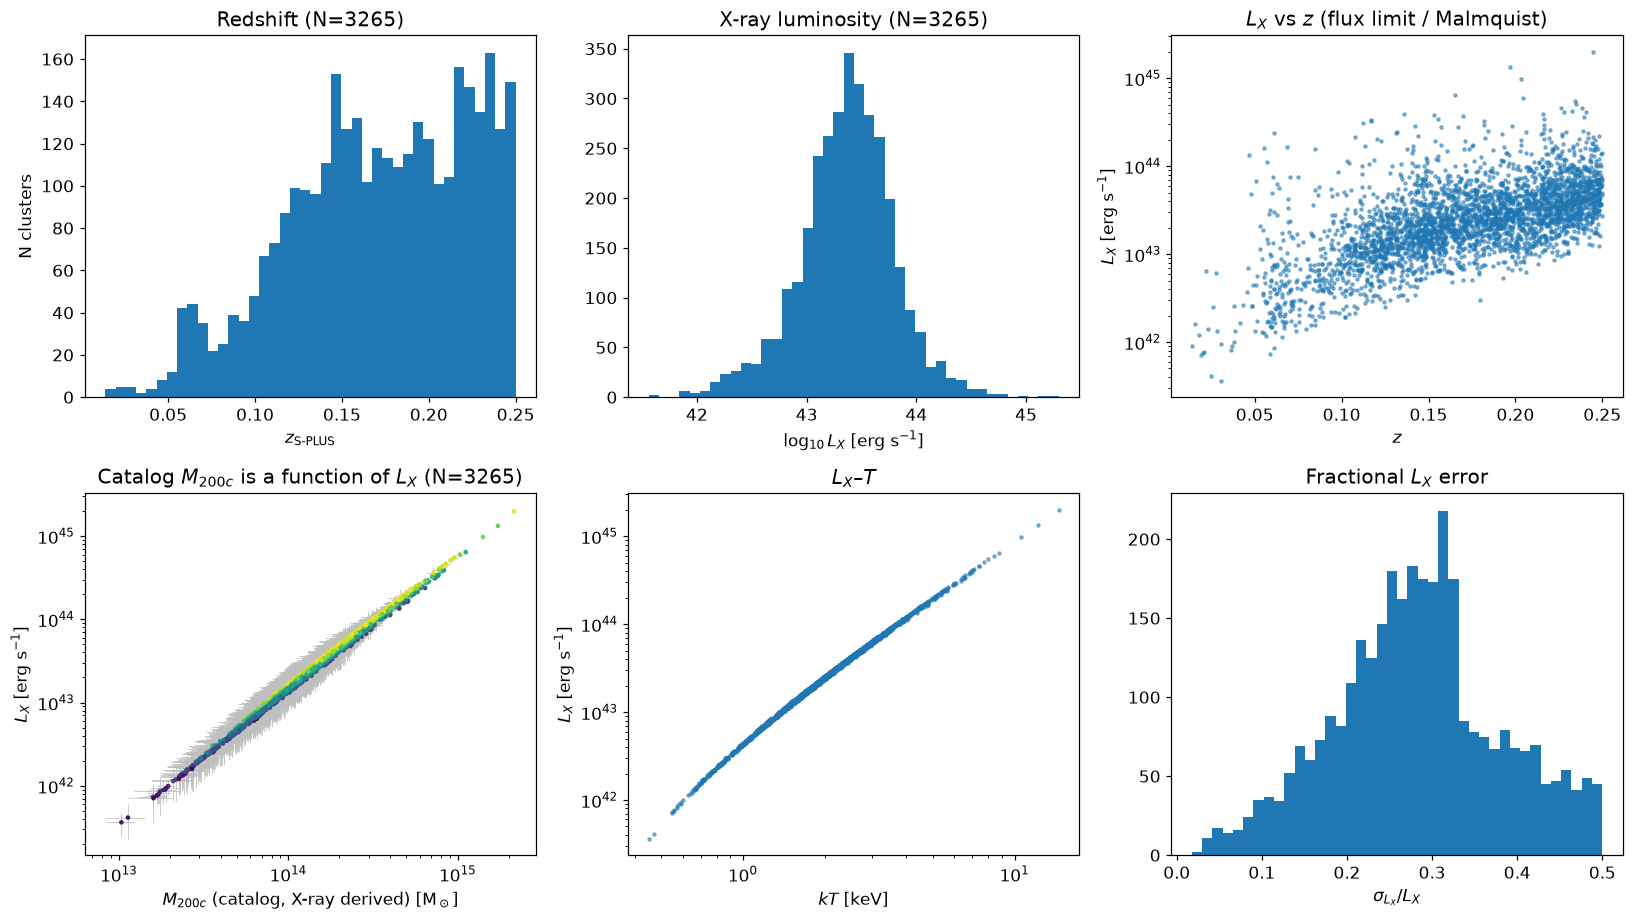

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8.5))
N = len(cl)

a = ax[0, 0]
a.hist(cl['z_splus'], bins=40, color='C0')
a.set_xlabel(r'$z_{\rm S\text{-}PLUS}$'); a.set_ylabel('N clusters'); a.set_title(f'Redshift (N={N})')

a = ax[0, 1]
a.hist(np.log10(cl['Lx']), bins=40, color='C0')
a.set_xlabel(r'$\log_{10} L_X$ [erg s$^{-1}$]'); a.set_title(f'X-ray luminosity (N={N})')

a = ax[0, 2]
a.scatter(cl['z_splus'], cl['Lx'], s=4, alpha=0.5, color='C0')
a.set_yscale('log'); a.set_xlabel(r'$z$'); a.set_ylabel(r'$L_X$ [erg s$^{-1}$]')
a.set_title(r'$L_X$ vs $z$ (flux limit / Malmquist)')

a = ax[1, 0]
a.errorbar(cl['M200c'], cl['Lx'], xerr=cl['eM200c'], yerr=cl['eLx'], fmt='none',
           ecolor='0.75', lw=0.5, zorder=1)
a.scatter(cl['M200c'], cl['Lx'], s=4, c=cl['z_splus'], cmap='viridis', zorder=2)
a.set_xscale('log'); a.set_yscale('log')
a.set_xlabel(r'$M_{200c}$ (catalog, X-ray derived) [M$_\odot$]'); a.set_ylabel(r'$L_X$ [erg s$^{-1}$]')
a.set_title(f'Catalog $M_{{200c}}$ is a function of $L_X$ (N={N})')

a = ax[1, 1]
a.scatter(cl['kT'], cl['Lx'], s=4, alpha=0.5, color='C0')
a.set_xscale('log'); a.set_yscale('log')
a.set_xlabel(r'$kT$ [keV]'); a.set_ylabel(r'$L_X$ [erg s$^{-1}$]'); a.set_title(r'$L_X$–$T$')

a = ax[1, 2]
a.hist(cl['eLx'] / cl['Lx'], bins=40, color='C0')
a.set_xlabel(r'$\sigma_{L_X} / L_X$'); a.set_title('Fractional $L_X$ error')
plt.tight_layout(); plt.show()

In [8]:
# Is kT also derived (from Lx), or measured?
print(f'corr(log Lx, log kT)  = {np.corrcoef(np.log10(cl["Lx"]), np.log10(cl["kT"]))[0,1]:.4f}')
print(f'corr(log Lx, log Lc)  = {np.corrcoef(np.log10(cl["Lx"]), np.log10(cl["Lc"]))[0,1]:.4f}'
      f'   median Lx/Lc = {np.median(cl["Lx"]/cl["Lc"]):.3f}')
print(f'corr(log Lx, log Flux0623 + 2 log D_L) = '
      f'{np.corrcoef(np.log10(cl["Lx"]), np.log10(cl["Flux0623"] * COSMO.luminosity_distance(cl["z_splus"]).to_value(u.cm)**2))[0,1]:.4f}')

corr(log Lx, log kT)  = 0.9985
corr(log Lx, log Lc)  = 0.9998   median Lx/Lc = 1.090
corr(log Lx, log Flux0623 + 2 log D_L) = 0.9992


Two features of the plots above:

- **`kT` lies on a curve of $L_X$ with no scatter.** SCALE II estimates the temperature iteratively from the Markevitch (1998) $L$–$T$ relation, as part of the K-correction, so it is not measured. The same holds for `M200c` (Leauthaud+10 $L_X$–$M$); we will use our own lensing masses.
- **$\sigma_{L_X}/L_X$ stops exactly at 0.5.** SCALE II keeps X-ray sources with point-source-free flux above 2σ, so this is that selection cut. It belongs in the selection function of the $L_X$–$M$ fit. §7 shows that the flux limit also varies across the sky.

## 4 — Optical quantities and X-ray–optical centre offsets

**How the optical centre is defined.** PZWav builds 2D galaxy density maps in photo-z slices of $\Delta z = 0.01$, weighting each galaxy by its photo-z PDF. It convolves them with a difference-of-Gaussians kernel on 400–1400 kpc scales. The centre is the highest local peak within 1.5 Mpc and $\Delta z = 0.03$ (Doubrawa+24 §3.1; SCALE II §2.2.1). So it is a smoothed galaxy number-density peak, not a luminosity centroid or a BCG position.

**How the X-ray–optical match is made.** It does not use centres. The X-ray surface-brightness contour (wavelet scales 2–4′) is matched to the AME member galaxies with a modified Hausdorff distance (SCALE II §3). A large centre offset is therefore allowed by construction.

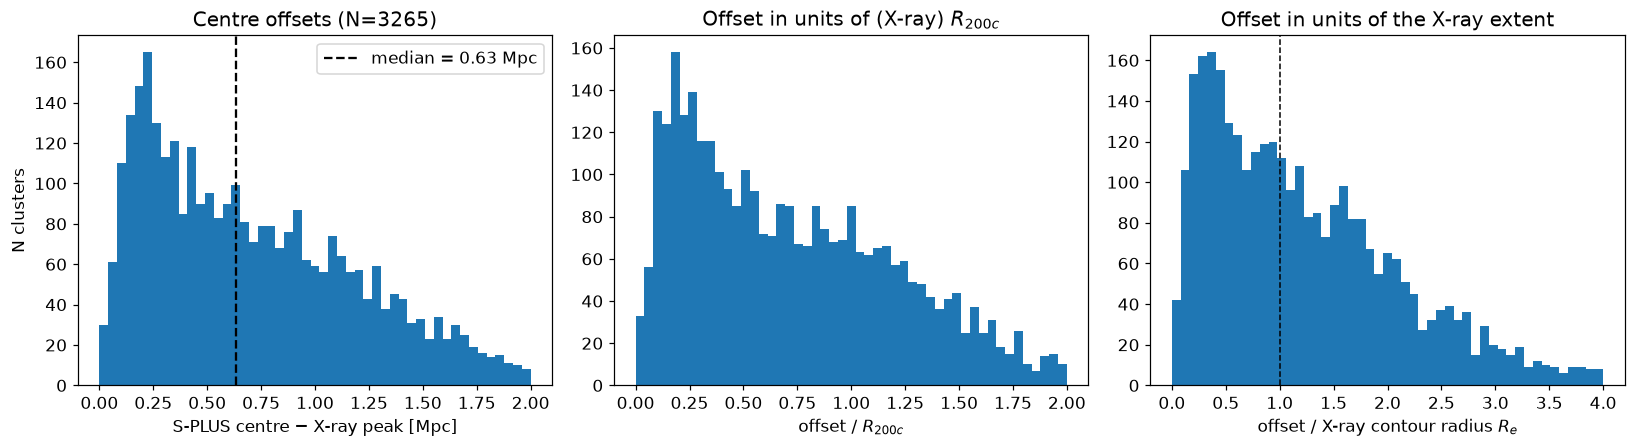

median R200c = 0.99 Mpc
offset percentiles 50/90/99/max: 0.63, 1.52, 2.89, 39.90 Mpc
offset median 3.85 arcmin vs X-ray Re_amin median 3.68 arcmin; within Re: 0.47, within 2 Re: 0.78
fraction with offset > 0.5 Mpc: 0.59;  > 2 Mpc (off the plot): 0.032


In [9]:
DA_cl = COSMO.angular_diameter_distance(cl['z_splus']).to_value(u.Mpc)
dra   = (np.asarray(cl['RA']) - np.asarray(cl['RA_peak']) + 180) % 360 - 180
ddec  = np.asarray(cl['DEC']) - np.asarray(cl['DEC_peak'])
off_deg = np.hypot(dra * np.cos(np.radians(cl['DEC'])), ddec)
off_mpc = np.radians(off_deg) * DA_cl
r200_mpc = np.radians(np.asarray(cl['R200c'])) * DA_cl     # R200c column is in degrees

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
a = ax[0]
a.hist(off_mpc, bins=np.linspace(0, 2, 50), color='C0')
a.axvline(np.median(off_mpc), color='k', ls='--', label=f'median = {np.median(off_mpc):.2f} Mpc')
a.set_xlabel('S-PLUS centre − X-ray peak [Mpc]'); a.set_ylabel('N clusters')
a.set_title(f'Centre offsets (N={len(cl)})'); a.legend()

a = ax[1]
a.hist(off_mpc / r200_mpc, bins=np.linspace(0, 2, 50), color='C0')
a.set_xlabel(r'offset / $R_{200c}$'); a.set_title('Offset in units of (X-ray) $R_{200c}$')

a = ax[2]
off_arcmin = off_deg * 60
a.hist(off_arcmin / np.asarray(cl['Re_amin']), bins=np.linspace(0, 4, 50), color='C0')
a.axvline(1, color='k', ls='--', lw=1)
a.set_xlabel(r'offset / X-ray contour radius $R_e$'); a.set_title('Offset in units of the X-ray extent')
plt.tight_layout(); plt.show()
print(f'median R200c = {np.median(r200_mpc):.2f} Mpc')
print(f'offset percentiles 50/90/99/max: ' + ', '.join(f'{v:.2f}' for v in np.percentile(off_mpc, [50, 90, 99, 100])) + ' Mpc')
print(f'offset median {np.median(off_arcmin):.2f} arcmin vs X-ray Re_amin median {np.median(cl["Re_amin"]):.2f} arcmin; '
      f'within Re: {np.mean(off_arcmin < cl["Re_amin"]):.2f}, within 2 Re: {np.mean(off_arcmin < 2 * cl["Re_amin"]):.2f}')
print(f'fraction with offset > 0.5 Mpc: {np.mean(off_mpc > 0.5):.2f};  > 2 Mpc (off the plot): {np.mean(off_mpc > 2):.3f}')

**The offsets beyond 2 Mpc.** These offsets reach several degrees, far beyond any X-ray contour. Do they cluster in particular eRASS1 tiles? And if they do, is it a row shuffle within the tile? (In that case each optical cluster would have its real X-ray peak elsewhere in the same tile.)

In [10]:
tile = np.asarray(cl['CID6722']) // 1000
bad  = off_mpc > 2
ut, cn = np.unique(tile[bad], return_counts=True)
o = np.argsort(cn)[::-1]
print(f'{bad.sum()} clusters with offset > 2 Mpc, spread over {len(ut)} tiles; top tiles:')
for tl, n in zip(ut[o][:6], cn[o][:6]):
    m = tile == tl
    sky_o = SkyCoord(cl['RA'][m], cl['DEC'][m], unit='deg')
    sky_x = SkyCoord(cl['RA_peak'][m], cl['DEC_peak'][m], unit='deg')
    _, d_nn, _ = sky_o.match_to_catalog_sky(sky_x)
    print(f'  tile {tl:06d}: {n:2d} of {m.sum():2d} rows > 2 Mpc;  median offset {np.median(off_arcmin[m]):6.1f} arcmin, '
          f'median offset to nearest X-ray peak in tile {np.median(d_nn.arcmin):6.1f} arcmin;  '
          f'tile centre RA, Dec ~ ({np.median(cl["RA"][m]):.0f}, {np.median(cl["DEC"][m]):.0f}) deg')

104 clusters with offset > 2 Mpc, spread over 71 tiles; top tiles:
  tile 071150: 16 of 17 rows > 2 Mpc;  median offset   66.7 arcmin, median offset to nearest X-ray peak in tile   24.5 arcmin;  tile centre RA, Dec ~ (72, -59) deg
  tile 042144:  6 of  6 rows > 2 Mpc;  median offset   40.6 arcmin, median offset to nearest X-ray peak in tile   22.3 arcmin;  tile centre RA, Dec ~ (43, -54) deg
  tile 038132:  5 of  5 rows > 2 Mpc;  median offset   89.5 arcmin, median offset to nearest X-ray peak in tile   69.2 arcmin;  tile centre RA, Dec ~ (40, -42) deg
  tile 188090:  3 of  6 rows > 2 Mpc;  median offset    7.1 arcmin, median offset to nearest X-ray peak in tile    7.1 arcmin;  tile centre RA, Dec ~ (187, -1) deg
  tile 155117:  2 of 13 rows > 2 Mpc;  median offset    3.1 arcmin, median offset to nearest X-ray peak in tile    3.1 arcmin;  tile centre RA, Dec ~ (155, -27) deg
  tile 199108:  2 of  5 rows > 2 Mpc;  median offset    7.2 arcmin, median offset to nearest X-ray peak in tile 

Three tiles (071150, 042144, 038132) account for a large share of the >2 Mpc offsets, and in 071150 almost every row is affected. Pairing each optical cluster with the nearest X-ray peak in the same tile does not bring the offsets down to the usual few arcmin. So this is not a simple row shuffle: the X-ray peak positions or the matches in these tiles look wrong. These three tiles lie inside the DES footprint (RA ≈ 40–75°, Dec ≈ −42° to −60°), so they matter for the lensing sample. For now we flag them; a later cut on the offset may be needed.

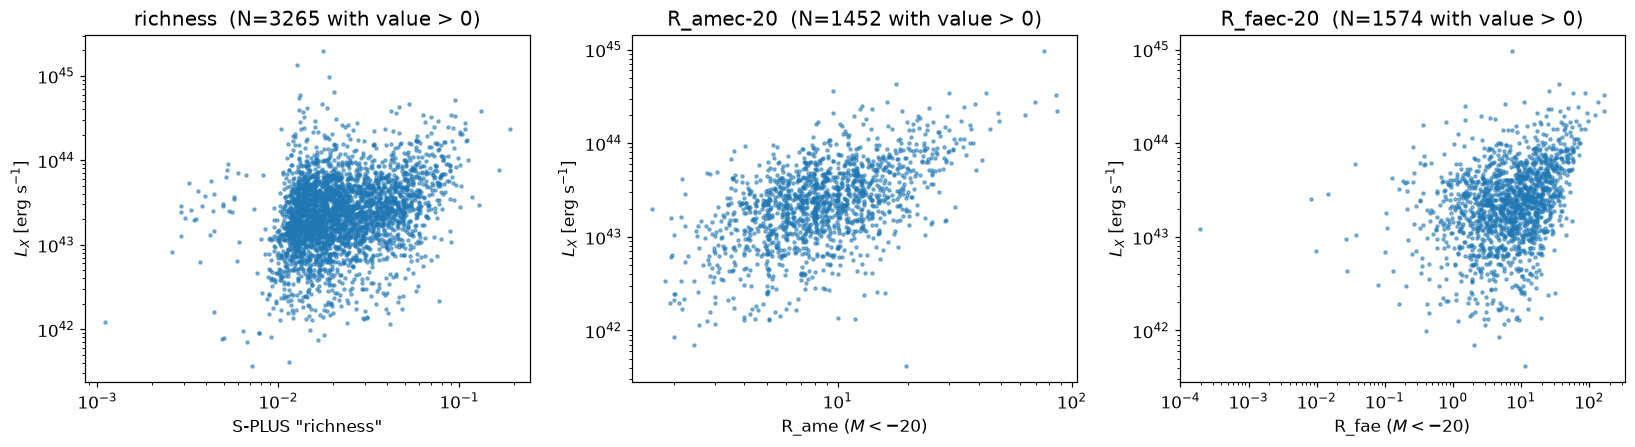

R_amec-20    (volume-limited to z<0.25): finite  3265, > 0:  1452, clusters with z<0.25:  3265
R_ame-19.5   (volume-limited to z<0.2): finite  2121, > 0:   932, clusters with z<0.2:  2121
R_ame-19     (volume-limited to z<0.15): finite  1125, > 0:   491, clusters with z<0.15:  1125
R_ame-18.5   (volume-limited to z<0.13): finite   729, > 0:   297, clusters with z<0.13:   729

p80: flagged in 2933 of 3265 clusters
p90: flagged in 2052 of 3265 clusters
p95: flagged in 974 of 3265 clusters
z < 0.08 (below the SCALE II range): 186 clusters
Rc-20 [kpc] percentiles 1/50/99: Rc-20 
------
 617.0
1021.0
1683.0
opt_lumc-20 max = 2.79e+24 Lsun  vs opt_lum-19 max = 3.00e+12 Lsun


In [11]:
# Richness-like optical columns: "richness" (S-PLUS), and the R_ame / R_fae counts per limiting magnitude
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (col, lab) in zip(ax, [('richness', 'S-PLUS "richness"'),
                             ('R_amec-20', r'R_ame ($M<-20$)'),
                             ('R_faec-20', r'R_fae ($M<-20$)')]):
    x = np.asarray(cl[col], dtype=float)
    ok = np.isfinite(x) & (x > 0)
    a.scatter(x[ok], cl['Lx'][ok], s=4, alpha=0.5, color='C0')
    a.set_xscale('log'); a.set_yscale('log')
    a.set_xlabel(lab); a.set_ylabel(r'$L_X$ [erg s$^{-1}$]')
    a.set_title(f'{col}  (N={ok.sum()} with value > 0)')
plt.tight_layout(); plt.show()
zlim = {'R_amec-20': 0.25, 'R_ame-19.5': 0.20, 'R_ame-19': 0.15, 'R_ame-18.5': 0.13}   # volume limits (SCALE II §2.2.2)
zc = np.asarray(cl['z_splus'])
for col, zl in zlim.items():
    x = np.asarray(cl[col].filled(np.nan) if hasattr(cl[col], 'filled') else cl[col], dtype=float)
    print(f'{col:12s} (volume-limited to z<{zl}): finite {np.isfinite(x).sum():5d}, > 0: {(x > 0).sum():5d}, '
          f'clusters with z<{zl}: {(zc < zl).sum():5d}')
print()
for c in ['p80', 'p90', 'p95']:
    print(f'{c}: flagged in {(~cl[c].mask).sum()} of {len(cl)} clusters')
print(f'z < 0.08 (below the SCALE II range): {(zc < 0.08).sum()} clusters')
print(f'Rc-20 [kpc] percentiles 1/50/99: {np.percentile(cl["Rc-20"], [1, 50, 99]).round(0)}')
print(f'opt_lumc-20 max = {np.nanmax(cl["opt_lumc-20"]):.2e} Lsun  vs opt_lum-19 max = {np.nanmax(cl["opt_lum-19"].filled(np.nan)):.2e} Lsun')

**AME and matching columns.**
- `R_ame*` is the AME richness ($\lambda = \sum P_{\rm mem}$) for each $M_r$ cut. The fainter cuts are only volume-complete at lower $z$, which is why they are filled for fewer clusters.
- `p80`/`p90`/`p95` flag the clusters that survive the matching at each purity level. A purity choice will be part of the lensing-sample selection.
- `opt_lumc-20` and `opt_mass_errc-20` contain values that can't be physical (up to $\sim10^{24}$ L$_\odot$ and $10^{27}$ M$_\odot$), so the `c-20` set needs checking with the provider.
- `R_fae*` is not defined in either paper. It can be negative and correlates with `R_ame` at 0.82, so it may be a background-subtracted richness.

## 5 — DES Y3 metacal source density (HEALPix)

Count sources per `NSIDE_SRC` pixel, then divide by pixel area to get the raw density $n = N/\Omega_{\rm pix}$ in arcmin$^{-2}$. A second map holds the effective density from the metacal weights, $n_{\rm eff} = (\sum w)^2 / \sum w^2 / \Omega_{\rm pix}$. Only RA/Dec/w are read. In this file **RA/Dec are stored in radians**, so they are converted to degrees first. Results are cached to `SRC_MAP_CACHE`.

In [12]:
if USE_CACHE and os.path.exists(SRC_MAP_CACHE):
    m = np.load(SRC_MAP_CACHE)
    cnt, sw, sw2 = m['cnt'], m['sw'], m['sw2']
    print(f'loaded cached source maps from {SRC_MAP_CACHE}')
else:
    src = np.load(SOURCE_FILE)
    ra, dec = np.degrees(src['ra']), np.degrees(src['dec'])   # stored in RADIANS in this file
    pix = hp.ang2pix(NSIDE_SRC, ra, dec, lonlat=True)
    del ra, dec
    w = src['w'].astype(np.float64)
    npix = hp.nside2npix(NSIDE_SRC)
    cnt = np.bincount(pix, minlength=npix).astype(np.float64)
    sw  = np.bincount(pix, weights=w, minlength=npix)
    sw2 = np.bincount(pix, weights=w**2, minlength=npix)
    del pix, w
    np.savez(SRC_MAP_CACHE, cnt=cnt, sw=sw, sw2=sw2)
    print(f'built and cached source maps -> {SRC_MAP_CACHE}')

pix_area = hp.nside2pixarea(NSIDE_SRC, degrees=True) * 3600.0     # arcmin^2
n_raw = cnt / pix_area
n_eff = np.where(sw2 > 0, sw**2 / np.where(sw2 > 0, sw2, 1), 0) / pix_area
occupied = cnt > 0
print(f'N sources = {cnt.sum():,.0f};  occupied pixels: {occupied.sum():,} '
      f'-> footprint area ~ {occupied.sum() * pix_area / 3600:,.0f} deg^2 (NSIDE={NSIDE_SRC})')
print(f'mean raw density   (occupied pixels): {cnt.sum() / (occupied.sum() * pix_area):.2f} arcmin^-2')
print(f'median n_eff per occupied pixel     : {np.median(n_eff[occupied]):.2f} arcmin^-2')

loaded cached source maps from /home/andre/destacking_data/lx_splus_erosita_des/des_metacal_counts_nside512.npz
N sources = 126,719,902;  occupied pixels: 400,221 -> footprint area ~ 5,248 deg^2 (NSIDE=512)
mean raw density   (occupied pixels): 6.71 arcmin^-2
median n_eff per occupied pixel     : 5.55 arcmin^-2


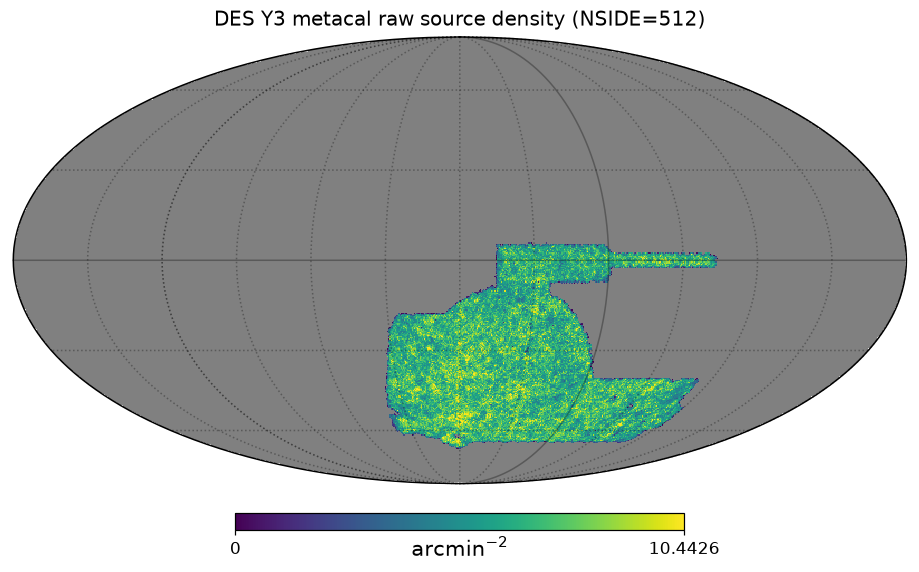

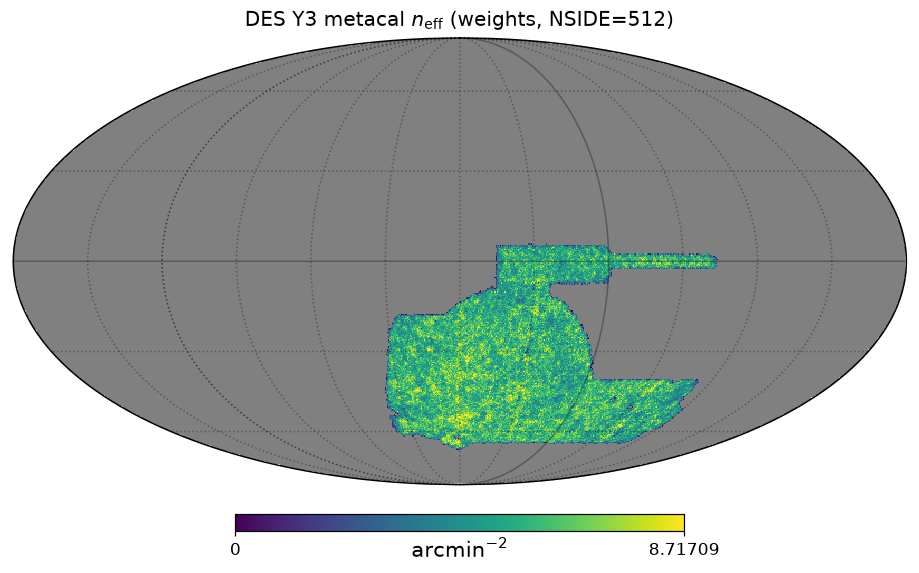

In [13]:
# Common projection for every map in this notebook
PROJ = dict(rot=(60, 0, 0), flip='astro', graticule=True)   # Mollweide, RA=60 deg at centre, RA increasing left

def show_mollview(mapvals, title, unit, **kw):
    hp.mollview(mapvals, title=title, unit=unit, rot=PROJ['rot'], flip=PROJ['flip'], **kw)
    hp.graticule(dpar=30, dmer=30, alpha=0.3)

m_raw = np.where(occupied, n_raw, hp.UNSEEN)
show_mollview(m_raw, f'DES Y3 metacal raw source density (NSIDE={NSIDE_SRC})',
              r'arcmin$^{-2}$', cmap='viridis', min=0, max=np.percentile(n_raw[occupied], 99))
plt.show()

m_eff = np.where(occupied, n_eff, hp.UNSEEN)
show_mollview(m_eff, rf'DES Y3 metacal $n_{{\rm eff}}$ (weights, NSIDE={NSIDE_SRC})',
              r'arcmin$^{-2}$', cmap='viridis', min=0, max=np.percentile(n_eff[occupied], 99))
plt.show()

## 6 — Cluster positions, same projection

Two views: (a) a HEALPix count map of the deduplicated clusters at `NSIDE_CL`; (b) the individual S-PLUS centres plotted over the DES source-density map.

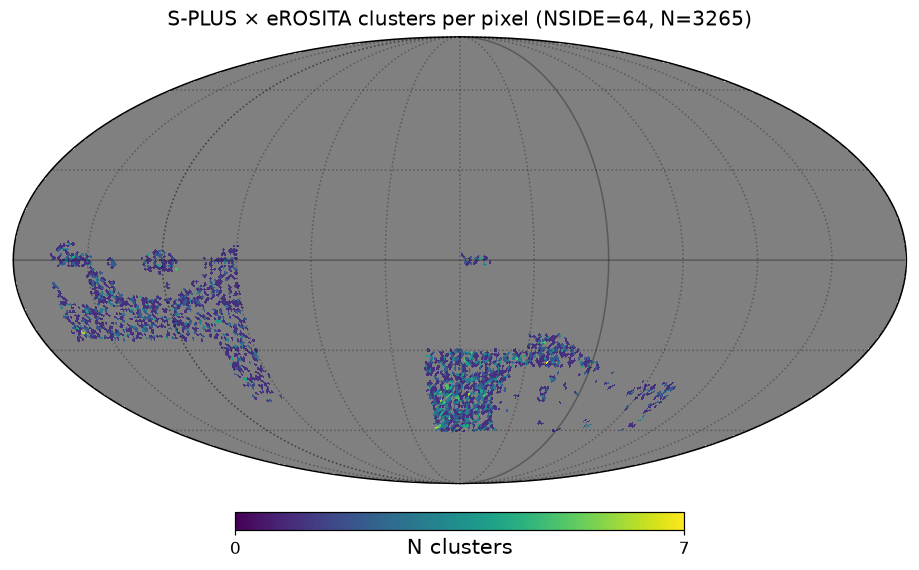

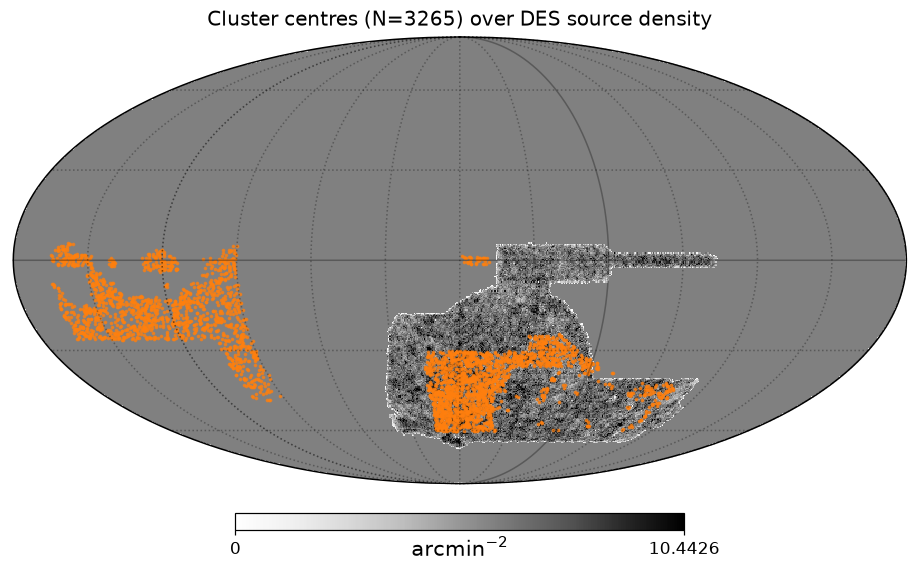

In [14]:
pix_cl = hp.ang2pix(NSIDE_CL, np.asarray(cl['RA']), np.asarray(cl['DEC']), lonlat=True)
cl_map = np.bincount(pix_cl, minlength=hp.nside2npix(NSIDE_CL)).astype(float)
show_mollview(np.where(cl_map > 0, cl_map, hp.UNSEEN),
              f'S-PLUS × eROSITA clusters per pixel (NSIDE={NSIDE_CL}, N={len(cl)})',
              'N clusters', cmap='viridis', min=0)
plt.show()

show_mollview(m_raw, f'Cluster centres (N={len(cl)}) over DES source density',
              r'arcmin$^{-2}$', cmap='Greys', min=0, max=np.percentile(n_raw[occupied], 99))
hp.projscatter(np.asarray(cl['RA']), np.asarray(cl['DEC']), lonlat=True,
               s=2, color='C1', alpha=0.7)
plt.show()

## 7 — Which clusters lie inside the DES footprint?

A cluster counts as inside if the source pixel at its centre is occupied. That alone isn't enough for lensing, because a cluster near the edge loses part of its annulus. So we also record the fraction of occupied source pixels within a disc of radius `R_CHECK_MPC` around each centre, and require it to be ≥ `MIN_COVER`.

In [15]:
R_CHECK_MPC = 3.0     # outer radius of a typical lensing profile
MIN_COVER   = 0.8

vec = hp.ang2vec(np.asarray(cl['RA']), np.asarray(cl['DEC']), lonlat=True)
theta_chk = R_CHECK_MPC / DA_cl                         # radians
cover = np.empty(len(cl))
for i in range(len(cl)):
    disc = hp.query_disc(NSIDE_SRC, vec[i], theta_chk[i], inclusive=False)
    cover[i] = occupied[disc].mean() if len(disc) else float(occupied[hp.vec2pix(NSIDE_SRC, *vec[i])])

centre_in = occupied[hp.ang2pix(NSIDE_SRC, np.asarray(cl['RA']), np.asarray(cl['DEC']), lonlat=True)]
in_des = centre_in & (cover >= MIN_COVER)
cl['des_cover'] = cover
cl['in_des']    = in_des
print(f'centre in an occupied DES pixel: {centre_in.sum()} / {len(cl)}')
print(f'+ >= {MIN_COVER:.0%} of the {R_CHECK_MPC} Mpc disc covered: {in_des.sum()} / {len(cl)}')

centre in an occupied DES pixel: 1731 / 3265
+ >= 80% of the 3.0 Mpc disc covered: 1731 / 3265


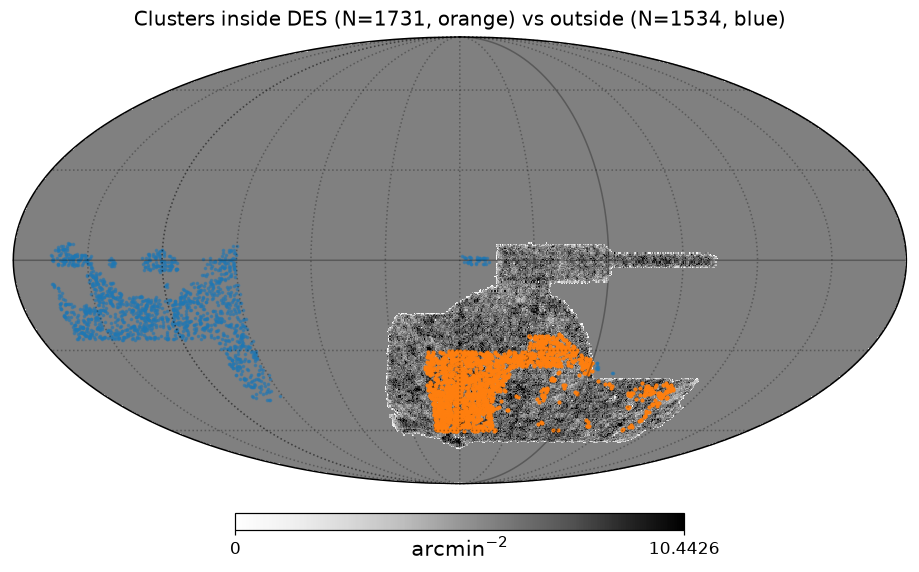

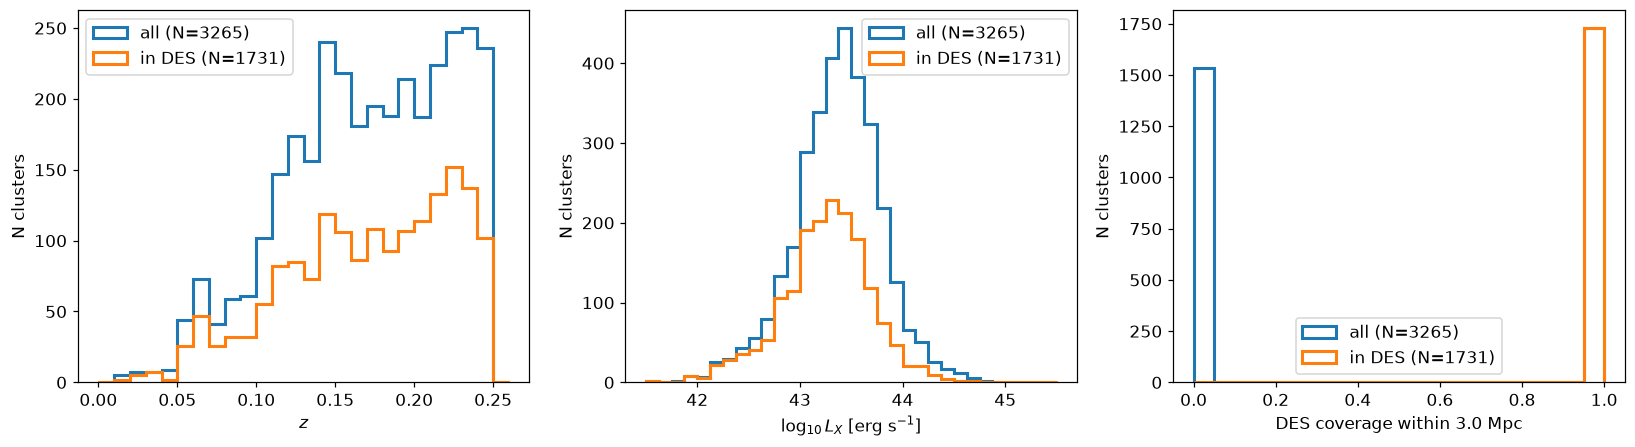

In [16]:
show_mollview(m_raw, f'Clusters inside DES (N={in_des.sum()}, orange) vs outside (N={(~in_des).sum()}, blue)',
              r'arcmin$^{-2}$', cmap='Greys', min=0, max=np.percentile(n_raw[occupied], 99))
hp.projscatter(np.asarray(cl['RA'])[~in_des], np.asarray(cl['DEC'])[~in_des], lonlat=True, s=2, color='C0', alpha=0.5)
hp.projscatter(np.asarray(cl['RA'])[in_des],  np.asarray(cl['DEC'])[in_des],  lonlat=True, s=3, color='C1', alpha=0.9)
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
sel = [(slice(None), f'all (N={len(cl)})', 'C0'), (in_des, f'in DES (N={in_des.sum()})', 'C1')]
for a, (x, xl, b) in zip(ax, [(np.asarray(cl['z_splus']), r'$z$', np.linspace(0, 0.26, 27)),
                              (np.log10(np.asarray(cl['Lx'])), r'$\log_{10} L_X$ [erg s$^{-1}$]', np.linspace(41.5, 45.5, 33)),
                              (cover, f'DES coverage within {R_CHECK_MPC} Mpc', np.linspace(0, 1, 21))]):
    for s, lab, c in sel:
        a.hist(x[s], bins=b, histtype='step', lw=2, color=c, label=lab)
    a.set_xlabel(xl); a.set_ylabel('N clusters'); a.legend()
plt.tight_layout(); plt.show()

**What this shows.** The coverage fraction is all-or-nothing: a cluster is either completely inside DES or completely outside, so the edge cut removes nothing. The S-PLUS×eROSITA clusters inside DES are those in the southern S-PLUS fields that overlap DES; the ones outside lie mostly in a separate S-PLUS region at RA ≈ 150–240°, Dec ≈ −43° to +4° (plus 37 clusters at RA ≈ 30–60° and a handful elsewhere). The clusters inside DES are fainter in X-rays: median $\log_{10} L_X$ = 43.28, against 43.49 for those outside. Both groups have the same median redshift (0.177 vs 0.173), so the 0.2 dex shift is not a redshift effect. The next cell tests whether it comes from eRASS1 depth.

**eRASS1 depth.** The eROSITA survey scans great circles through the ecliptic poles, so exposure rises steeply towards the poles. The DES footprint surrounds the south ecliptic pole region, while the S-PLUS region outside DES lies near the ecliptic plane. If depth is the cause, the clusters inside DES should have smaller flux errors and reach lower fluxes.

in DES       (N=1731): median |ecliptic lat| =  56.3 deg;  median eFlux = 4.19e-14;  5th-pct flux = 5.72e-14;  median log Lx = 43.28   (fluxes: 0.6-2.3 keV, erg/s/cm^2)
outside DES  (N=1534): median |ecliptic lat| =  13.9 deg;  median eFlux = 6.65e-14;  5th-pct flux = 1.20e-13;  median log Lx = 43.49   (fluxes: 0.6-2.3 keV, erg/s/cm^2)
corr(|ecliptic lat|, log eFlux) over all clusters = -0.53


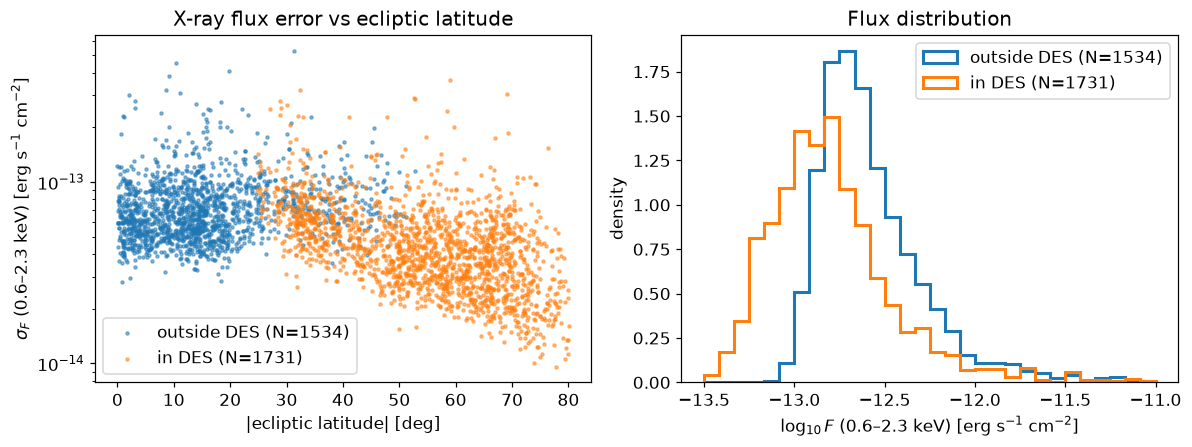

In [17]:
beta = SkyCoord(cl['RA'], cl['DEC'], unit='deg').barycentrictrueecliptic.lat.deg
flux, eflux = np.asarray(cl['Flux0623']), np.asarray(cl['eFlux0623'])
for lab, s in [('in DES', in_des), ('outside DES', ~in_des)]:
    print(f'{lab:12s} (N={s.sum():4d}): median |ecliptic lat| = {np.median(np.abs(beta[s])):5.1f} deg;  '
          f'median eFlux = {np.median(eflux[s]):.2e};  5th-pct flux = {np.percentile(flux[s], 5):.2e};  '
          f'median log Lx = {np.median(np.log10(cl["Lx"][s])):.2f}   (fluxes: 0.6-2.3 keV, erg/s/cm^2)')
print(f'corr(|ecliptic lat|, log eFlux) over all clusters = {np.corrcoef(np.abs(beta), np.log10(eflux))[0,1]:.2f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
a = ax[0]
a.scatter(np.abs(beta)[~in_des], eflux[~in_des], s=4, alpha=0.5, color='C0', label=f'outside DES (N={(~in_des).sum()})')
a.scatter(np.abs(beta)[in_des],  eflux[in_des],  s=4, alpha=0.5, color='C1', label=f'in DES (N={in_des.sum()})')
a.set_yscale('log'); a.set_xlabel(r'|ecliptic latitude| [deg]'); a.set_ylabel(r'$\sigma_F$ (0.6–2.3 keV) [erg s$^{-1}$ cm$^{-2}$]')
a.set_title('X-ray flux error vs ecliptic latitude'); a.legend()
a = ax[1]
b = np.linspace(-13.5, -11, 31)
for lab, s, c in [(f'outside DES (N={(~in_des).sum()})', ~in_des, 'C0'), (f'in DES (N={in_des.sum()})', in_des, 'C1')]:
    a.hist(np.log10(flux[s]), bins=b, histtype='step', lw=2, color=c, label=lab, density=True)
a.set_xlabel(r'$\log_{10} F$ (0.6–2.3 keV) [erg s$^{-1}$ cm$^{-2}$]'); a.set_ylabel('density'); a.legend()
a.set_title('Flux distribution')
plt.tight_layout(); plt.show()

**Result.** The clusters inside DES lie at much higher ecliptic latitude, have smaller flux errors, and reach roughly half the flux of those outside. So the $L_X$ shift comes from the position-dependent eRASS1 flux limit. **The selection function of the $L_X$–$M$ fit needs this varying flux limit** (via the eRASS1 exposure map, or with $\sigma_F$ as a proxy), not a single threshold. The sub-sample inside DES defines the lensing selection.

In [18]:
# Rough source budget per in-DES cluster: raw source density at the centre pixel, and the
# expected number of sources inside R_CHECK_MPC (all redshifts -- no background cut yet).
pix_c = hp.ang2pix(NSIDE_SRC, np.asarray(cl['RA']), np.asarray(cl['DEC']), lonlat=True)
n_centre = n_raw[pix_c]
area_arcmin2 = np.pi * (np.degrees(theta_chk) * 60)**2
n_expect = n_centre * area_arcmin2 * cover
print(f'in-DES clusters (N={in_des.sum()}): median raw density at centre = {np.median(n_centre[in_des]):.2f} arcmin^-2; '
      f'median sources within {R_CHECK_MPC} Mpc (all z) = {np.median(n_expect[in_des]):,.0f}')

in-DES clusters (N=1731): median raw density at centre = 8.07 arcmin^-2; median sources within 3.0 Mpc (all z) = 7,034


## Open questions for the catalog provider

Most of the original questions are answered by SCALE II ([arXiv:2607.02706](https://arxiv.org/abs/2607.02706)) and Doubrawa et al. 2024 ([arXiv:2312.12197](https://arxiv.org/abs/2312.12197)). These remain:

1. **Version of the file.** Is this an intermediate eSCALE file? It still has the tile duplicates that SCALE II says the final catalog removes (506 clusters with 2–4 rows). Which magnitude cut and purity level does it correspond to? `p80` is set for 90% of clusters, so the parent sample may be the 70% purity one shown in the SCALE II appendices. Is there a final, deduplicated version we should use instead?
2. **`Lx` vs `Lc`.** SCALE II mentions both a point-source-cleaned luminosity and a full one. Which column is which, and within which aperture (`Rap2R500`?)? The ratio is 1.02–1.13 and is not `Acor`.
3. **Large offsets in tiles 071150, 042144, 038132.** These tiles are inside DES. Many of their optical–X-ray offsets are of order a degree, and re-pairing within the tile doesn't fix them. Are their `RA_peak`/`DEC_peak` values, or the matches themselves, wrong?
4. **BCG positions.** The S-PLUS centre is the PZWav density peak, smoothed on 400–1400 kpc. Can we get BCG positions (e.g. from the AME members) to compare with the X-ray peak and choose the lensing centre?
5. **Undocumented columns.** What are `R_fae*` (can be negative), `richness` (0.001–0.19, tracks SNR), `rank` and `SNR_ORIG`, and what does the `c` in `*c-20` mean? `opt_lumc-20` and `opt_mass_errc-20` contain values up to $10^{24}$–$10^{27}$. `radius` is a copy of `SNR`, and one `SNR` is inf.
6. **Selection.** Besides the 2σ point-source-free flux cut, the S/N ≥ 4 PZWav threshold and the matching criteria, are there other cuts? Can we get the eRASS1 exposure or sensitivity map for the S-PLUS footprint? The flux limit varies strongly with ecliptic latitude (§7).
7. **Low redshift.** 186 clusters have $z < 0.08$, below the SCALE II range. Should we keep them, given the Horologium–Reticulum supercluster?